# TF-IDF Baseline Models

In [24]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 70
N_JOBS = 6 #change depending on number of cores
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load

In [25]:
df = pd.read_parquet("data_clean/wine_reviews_clean.parquet")
df.shape

(119922, 16)

## Train / validation / test split

In [26]:
strata = df["country_group"].fillna("Unknown")
train, rest = train_test_split(df, test_size=0.3, stratify=strata, random_state=SEED)
val, test = train_test_split(rest, test_size=0.5, stratify=strata[rest.index], random_state=SEED)
len(train), len(val), len(test)

(83945, 17988, 17989)

In [27]:
pd.DataFrame({name: split["country"].value_counts(normalize=True).head(8) * 100 for name, split in
              [("train", train), ("val", val), ("test", test)]}).round(1)

,train,val,test
country,,,
US,42.1,42.1,42.1
France,17.0,17.0,17.0
Italy,14.9,14.9,14.9
Spain,5.1,5.1,5.1
Portugal,4.4,4.4,4.4
Chile,3.5,3.5,3.5
Argentina,3.0,3.0,3.0
Austria,2.5,2.5,2.5


In [28]:
split_dir = Path("data_clean/splits")
split_dir.mkdir(exist_ok=True)
for name, split in [("train", train), ("val", val), ("test", test)]:
    split.to_parquet(split_dir / f"{name}.parquet", index=False)

## TF-IDF features

In [29]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_train = vectorizer.fit_transform(train["description"])
X_val = vectorizer.transform(val["description"])
X_test = vectorizer.transform(test["description"])
X_train.shape

(83945, 20000)

## Targets

In [30]:
keep = {}
summary = []
for target in TARGETS:
    counts = train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({
        "target": target,
        "all_classes": train[target].nunique(),
        "kept_classes": len(keep[target]),
        "pct_missing": train[target].isna().mean() * 100,
        "pct_rows_kept": train[target].isin(keep[target]).mean() * 100,
    })
pd.DataFrame(summary).set_index("target").round(1)

,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,40,18,0.0,99.3
province,395,80,0.0,95.7
region_1,1162,193,16.3,69.0


In [31]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask]

## Baseline models

In [32]:
def make_models():
    return {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS),
        "Decision tree": DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED),
    }

In [33]:
fitted = {}
results = []
for target in TARGETS:
    Xt, yt = subset(train, X_train, target)
    Xv, yv = subset(val, X_val, target)
    for name, model in make_models().items():
        start = time.perf_counter()
        with parallel_config(max_nbytes=None):
            model.fit(Xt, yt)
        fit_seconds = time.perf_counter() - start
        pred = model.predict(Xv)
        fitted[target, name] = model
        results.append({
            "target": target,
            "model": name,
            "train_accuracy": accuracy_score(yt, model.predict(Xt)),
            "accuracy": accuracy_score(yv, pred),
            "macro_F1": f1_score(yv, pred, average="macro", zero_division=0),
            "fit_seconds": fit_seconds,
        })
results = pd.DataFrame(results).set_index(["target", "model"])
results.round(3)

train_accuracy  accuracy  macro_F1  \
target   model                                                       
country  Most frequent (dummy)           0.424     0.424     0.033   
         Logistic regression             0.969     0.858     0.571   
         Decision tree                   0.804     0.645     0.281   
province Most frequent (dummy)           0.292     0.298     0.006   
         Logistic regression             0.971     0.691     0.328   
         Decision tree                   0.600     0.424     0.118   
region_1 Most frequent (dummy)           0.050     0.050     0.000   
         Logistic regression             0.977     0.399     0.266   
         Decision tree                   0.322     0.187     0.086   

                                fit_seconds  
target   model                               
country  Most frequent (dummy)        0.026  
         Logistic regression          5.885  
         Decision tree               14.182  
province Most frequent (dummy)        0.021  
         Logistic regression         12.317  
         Decision tree               17.333  
region_1 Most frequent (dummy)        0.016  
         Logistic regression         17.613  
         Decision tree               19.797

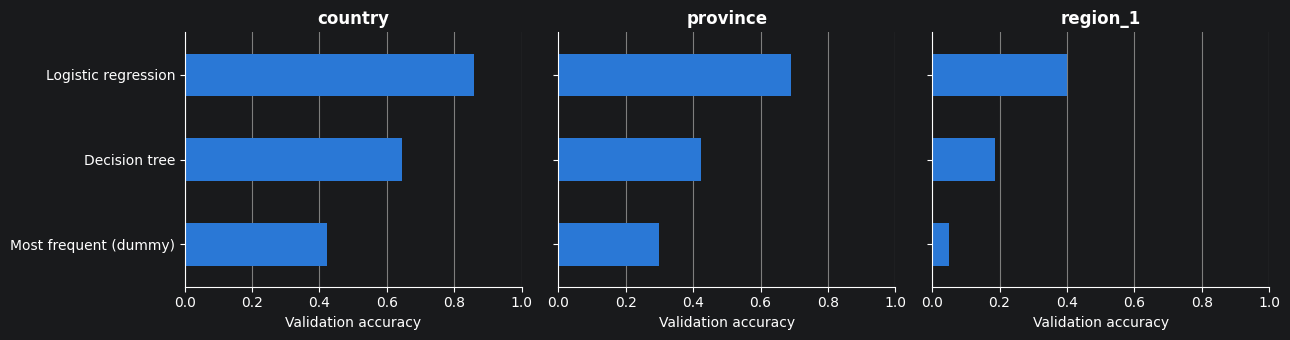

In [34]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 3.5), sharex=True)
for ax, target in zip(axes, TARGETS):
    results.loc[target, "accuracy"].sort_values().plot.barh(color=BLUE, ax=ax)
    ax.set(title=target, xlabel="Validation accuracy", ylabel="", xlim=(0, 1))
    ax.grid(axis="y", visible=False)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.tight_layout()

## Most predictive words by country

In [35]:
logreg = fitted["country", "Logistic regression"]
words = vectorizer.get_feature_names_out()
coefs = np.vstack([est.coef_[0] for est in logreg.estimators_])
top_words = {country: words[np.argsort(coef)[::-1][:8]] for country, coef in zip(logreg.classes_, coefs)}
pd.DataFrame(top_words).T

,0,1,2,3,4,5,6,7
Argentina,malbec,bonarda,torrontés,malbecs,aromas,argentina,argentine,flavors
Australia,shiraz,australian,australia,barossa,semillon,yellow fruit,cassis,chardonnay
Austria,screwcap,zweigelt,grüner,blaufränkisch,glass stopper,slender,stopper,pepper
Bulgaria,has aromas,flavors of,garnet,cherry,freshly,pleasantly,aromas of,finish
Canada,with notes,gewürz,honey,penetrating,lychee,grape,pure varietal,apricot
Chile,carmenère,chilean,chile,aromas,sb,carignan,olive,casablanca
France,champagne,garrigue,hermitage,château,clairette,provence,chablis,barrel sample
Germany,kabinett,auslese,spätlese,mosel,sweet,riesling,minerality,mineral
Greece,spin,greek,red,white,lead this,start this,lemon,dishes
Hungary,hungarian,honey,has,apricot,honeycomb,tart cherry,hefty,flavors of


## Most common country mistakes

In [36]:
Xv, yv = subset(val, X_val, "country")
mistakes = pd.DataFrame({"actual": yv, "predicted": logreg.predict(Xv)})
mistakes = mistakes[mistakes["actual"] != mistakes["predicted"]]
mistakes.value_counts().head(10).rename("reviews").to_frame()

reviews
actual    predicted         
Portugal  France         351
Argentina Spain          167
Chile     Spain          159
France    US             122
          Portugal       108
Austria   France          98
Australia US              93
Argentina Chile           92
Germany   US              92
Spain     Chile           91

In [37]:
per_country = pd.DataFrame({"actual": yv, "correct": logreg.predict(Xv) == yv})
per_country.groupby("actual")["correct"].agg(["size", "mean"]).sort_values("mean").round(3)

,size,mean
actual,,
Romania,15,0.000
Canada,34,0.000
Bulgaria,20,0.150
Hungary,20,0.200
Argentina,531,0.450
New Zealand,191,0.476
Israel,70,0.500
Chile,627,0.510
Portugal,788,0.528


## Taster vs country

In [38]:
country_train = train[train["country"].isin(keep["country"])]
country_val = val[val["country"].isin(keep["country"])].copy()
country_val["taster"] = country_val["taster_name"].fillna("Unknown")
country_val["predicted"] = logreg.predict(subset(val, X_val, "country")[0])
taster_country = country_train.groupby(country_train["taster_name"].fillna("Unknown"))["country"].agg(lambda s: s.mode()[0])
country_val["taster_guess"] = country_val["taster"].map(taster_country)
country_val["model_correct"] = country_val["predicted"] == country_val["country"]
country_val["taster_correct"] = country_val["taster_guess"] == country_val["country"]
country_val[["model_correct", "taster_correct"]].mean().round(3)

model_correct     0.858
taster_correct    0.745
dtype: float64

In [39]:
misleading = ~country_val["taster_correct"]
pd.Series({"reviews": misleading.sum(), "model_accuracy": country_val.loc[misleading, "model_correct"].mean()}).round(3)

reviews           4555.000
model_accuracy       0.618
dtype: float64

In [40]:
by_taster = country_val.groupby("taster").agg(
    reviews=("country", "size"),
    countries=("country", "nunique"),
    taster_only=("taster_correct", "mean"),
    text_model=("model_correct", "mean"),
)
by_taster.sort_values("reviews", ascending=False).round(3)

,reviews,countries,taster_only,text_model
taster,,,,
Unknown,3778,11,0.646,0.948
Roger Voss,3543,5,0.730,0.820
Michael Schachner,2067,6,0.439,0.600
Kerin O’Keefe,1445,1,1.000,0.996
Virginie Boone,1330,1,1.000,0.988
Paul Gregutt,1305,4,0.975,0.966
Matt Kettmann,889,1,1.000,0.991
Joe Czerwinski,701,10,0.402,0.561
Sean P. Sullivan,639,2,0.997,0.995


[Text(0.5, 1.0, 'Country accuracy vs how much the taster gives away'),
 Text(0.5, 0, "Taster-only accuracy (always guess the taster's main country)"),
 Text(0, 0.5, 'Text model accuracy'),
 (0.35, 1.04),
 (0.35, 1.04)]

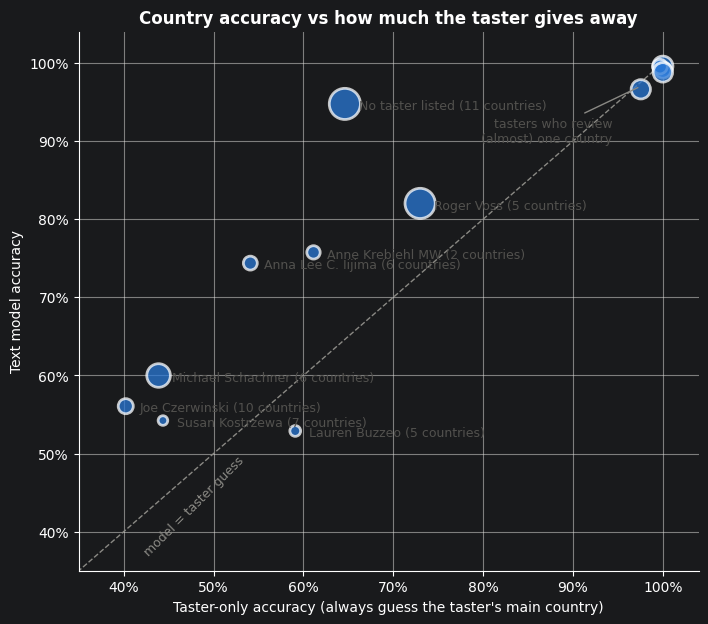

In [41]:
plot_data = by_taster[by_taster["reviews"] >= 100].rename(index={"Unknown": "No taster listed"})
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot([0, 1], [0, 1], color="#8a8984", linewidth=1, linestyle="--", zorder=1)
ax.scatter(plot_data["taster_only"], plot_data["text_model"], s=plot_data["reviews"] / 8 + 30,
           color=BLUE, alpha=0.75, edgecolor="white", linewidth=2, zorder=2)
for name, row in plot_data[plot_data["taster_only"] < 0.9].iterrows():
    ax.annotate(f"{name} ({int(row['countries'])} countries)", (row["taster_only"], row["text_model"]),
                xytext=(10, -4), textcoords="offset points", fontsize=9, color="#52514e")
ax.annotate("tasters who review\n(almost) one country", (0.975, 0.97), xytext=(-20, -40), textcoords="offset points",
            ha="right", fontsize=9, color="#52514e", arrowprops={"arrowstyle": "-", "color": "#8a8984"})
ax.text(0.42, 0.37, "model = taster guess", rotation=45, fontsize=9, color="#8a8984")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Country accuracy vs how much the taster gives away",
       xlabel="Taster-only accuracy (always guess the taster's main country)",
       ylabel="Text model accuracy", xlim=(0.35, 1.04), ylim=(0.35, 1.04))

In [42]:
taster_model = OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS)
with parallel_config(max_nbytes=None):
    taster_model.fit(X_train, train["taster_name"].fillna("Unknown"))
accuracy_score(val["taster_name"].fillna("Unknown"), taster_model.predict(X_val))

0.9714253947075828

## Joint accuracy

In [43]:
all_kept = np.all([val[t].isin(keep[t]) for t in TARGETS], axis=0)
joint_val = val[all_kept]
joint_pred = pd.DataFrame({t: fitted[t, "Logistic regression"].predict(X_val[all_kept]) for t in TARGETS},
                          index=joint_val.index)
joint_correct = joint_pred == joint_val[TARGETS]
all_kept.sum()

np.int64(12316)

In [44]:
joint_summary = joint_correct.mean()
joint_summary["all three"] = joint_correct.all(axis=1).mean()
joint_summary.round(3)

country      0.923
province     0.801
region_1     0.399
all three    0.342
dtype: float64

In [45]:
region_lookup = train.dropna(subset=["region_1"]).groupby("region_1")[["province", "country"]].agg(lambda s: s.mode()[0])
from_region = region_lookup.loc[joint_pred["region_1"]].set_axis(joint_val.index)
from_region["region_1"] = joint_pred["region_1"]
from_region_correct = from_region[TARGETS] == joint_val[TARGETS]
pd.DataFrame({"separate models": joint_correct.mean(), "from region": from_region_correct.mean()}).round(3)

,separate models,from region
country,0.923,0.936
province,0.801,0.803
region_1,0.399,0.399


In [46]:
province_lookup = train.groupby("province")["country"].agg(lambda s: s.mode()[0])
pd.Series({
    "region matches province": (from_region["province"] == joint_pred["province"]).mean(),
    "province matches country": (province_lookup.loc[joint_pred["province"]].to_numpy() == joint_pred["country"].to_numpy()).mean(),
}).round(3)

region matches province     0.830
province matches country    0.939
dtype: float64

## Test set

In [47]:
test_results = []
for target in TARGETS:
    best_name = results.loc[target, "macro_F1"].idxmax()
    Xs, ys = subset(test, X_test, target)
    pred = fitted[target, best_name].predict(Xs)
    test_results.append({
        "target": target,
        "model": best_name,
        "accuracy": accuracy_score(ys, pred),
        "macro_F1": f1_score(ys, pred, average="macro", zero_division=0),
    })
pd.DataFrame(test_results).set_index("target").round(3)

,model,accuracy,macro_F1
target,,,
country,Logistic regression,0.856,0.566
province,Logistic regression,0.695,0.346
region_1,Logistic regression,0.398,0.266
